# ERC Rock Detection with YOLO26 (Mars Rocks dataset)

A simple notebook for the RoboTeam Twente rock detector. It does these steps:

1. Download the Mars Rocks dataset from Roboflow (YOLO format)
2. Check the data and look at labeled examples
3. Train YOLO26n (one class: `rock`)
4. Measure precision, recall, F1 and mAP on the validation and test sets
5. Run the model on your own Mars Yard photos
6. Upload one photo and see the detected rocks in boxes



In [6]:
%pip install -U ultralytics roboflow matplotlib pandas pyyaml pillow ipywidgets


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\amirf\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 1. Settings

Change the Roboflow version number below. Open the dataset page, look at the Versions tab, and use the latest version number.

You need a free Roboflow API key (Roboflow, Settings, API Keys). The notebook asks for it when it downloads, or reads it from the `ROBOFLOW_API_KEY` environment variable.

In [ ]:
import os, random, getpass
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import ipywidgets as widgets
import torch
from ultralytics import YOLO

RF_WORKSPACE = "ritesh-laf7m"
RF_PROJECT   = "mars-rocks-detection"
RF_VERSION   = 1
DATASET_DIR  = Path("./mars_rocks")
ONE_CLASS    = True

MODEL_NAME = "yolo26n.pt"
IMG_SIZE   = 640
EPOCHS     = 100
BATCH      = 8
PATIENCE   = 20
CONF       = 0.25
DEVICE     = "cuda:0" if torch.cuda.is_available() else "cpu"
WORKERS    = 2

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    print("CUDA GPU not detected; using CPU. Training will be slower.")
print("Device selected:", DEVICE)
%pip install -U ultralytics roboflow matplotlib pandas pyyaml pillow ipywidgets
MARSYARD_DIR = Path("./marsyard_images")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CUDA GPU not detected; using CPU. Training will be slower.
Device selected: cpu


## 2. Download the dataset

If the folder already exists, the download is skipped.

In [8]:
if DATASET_DIR.exists() and any(DATASET_DIR.iterdir()):
    print("Dataset folder already exists, skipping download:", DATASET_DIR.resolve())
else:
    from roboflow import Roboflow
    api_key = os.environ.get("ROBOFLOW_API_KEY") or getpass.getpass("Roboflow API key: ")
    rf = Roboflow(api_key=api_key)
    project = rf.workspace(RF_WORKSPACE).project(RF_PROJECT)
    project.version(RF_VERSION).download("yolov8", location=str(DATASET_DIR))
    print("Downloaded to:", DATASET_DIR.resolve())

Dataset folder already exists, skipping download: C:\Users\amirf\Desktop\RoboTeam\Rock detection\mars_rocks


## 3. Prepare and check the data

This cell finds the train, validation and test folders, makes every class `rock` (if `ONE_CLASS` is on), and writes a clean `rock.yaml` for training. Read the printed class names. If the dataset has more than one class, make sure they are all rocks.

In [9]:
import json
import shutil

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

RAW_DATASET_DIR = DATASET_DIR
YOLO_DATASET_DIR = RAW_DATASET_DIR / "_yolo"

has_yolo_layout = (RAW_DATASET_DIR / "train" / "images").exists()
has_coco_layout = (RAW_DATASET_DIR / "train" / "_annotations.coco.json").exists()

if not has_yolo_layout and has_coco_layout:
    print("COCO annotations found; creating YOLO folders in:", YOLO_DATASET_DIR.resolve())
    for split in ("train", "valid", "test"):
        annotation_path = RAW_DATASET_DIR / split / "_annotations.coco.json"
        if not annotation_path.exists():
            continue

        split_output = YOLO_DATASET_DIR / split
        image_output = split_output / "images"
        label_output = split_output / "labels"
        image_output.mkdir(parents=True, exist_ok=True)
        label_output.mkdir(parents=True, exist_ok=True)

        coco = json.loads(annotation_path.read_text(encoding="utf-8"))
        categories = {item["id"]: item["name"] for item in coco.get("categories", [])}
        annotations_by_image = {}
        for annotation in coco.get("annotations", []):
            annotations_by_image.setdefault(annotation["image_id"], []).append(annotation)

        for image in coco.get("images", []):
            image_name = image["file_name"]
            source_image = RAW_DATASET_DIR / split / image_name
            if not source_image.exists():
                raise FileNotFoundError(f"Image listed in COCO file was not found: {source_image}")
            shutil.copy2(source_image, image_output / image_name)

            labels = []
            image_width, image_height = image["width"], image["height"]
            for annotation in annotations_by_image.get(image["id"], []):
                x, y, width, height = annotation["bbox"]
                center_x = (x + width / 2) / image_width
                center_y = (y + height / 2) / image_height
                normalized_width = width / image_width
                normalized_height = height / image_height
                class_id = 0 if ONE_CLASS else list(categories).index(annotation["category_id"])
                labels.append(
                    f"{class_id} {center_x:.6f} {center_y:.6f} "
                    f"{normalized_width:.6f} {normalized_height:.6f}"
                )

            label_path = label_output / f"{Path(image_name).stem}.txt"
            label_path.write_text("\n".join(labels) + ("\n" if labels else ""), encoding="utf-8")

    DATASET_DIR = YOLO_DATASET_DIR
elif has_yolo_layout:
    print("YOLO dataset layout found:", RAW_DATASET_DIR.resolve())
else:
    raise FileNotFoundError(
        f"Could not find YOLO folders or COCO annotations inside {RAW_DATASET_DIR.resolve()}"
    )

SPLIT_DIRS = {}
for split, options in {"train": ["train"], "val": ["valid", "val"], "test": ["test"]}.items():
    for folder in options:
        if (DATASET_DIR / folder / "images").exists():
            SPLIT_DIRS[split] = folder
            break

if "train" not in SPLIT_DIRS or "val" not in SPLIT_DIRS:
    raise FileNotFoundError(
        f"Need train and valid folders inside {DATASET_DIR.resolve()}. Found: {SPLIT_DIRS}"
    )

source_yaml = DATASET_DIR / "data.yaml"
if source_yaml.exists():
    src_cfg = yaml.safe_load(source_yaml.read_text(encoding="utf-8"))
    names = src_cfg["names"]
    if isinstance(names, list):
        names = {i: n for i, n in enumerate(names)}
else:
    coco_cfg = json.loads((RAW_DATASET_DIR / "train" / "_annotations.coco.json").read_text(encoding="utf-8"))
    category_names = [item["name"] for item in coco_cfg.get("categories", [])]
    names = {i: name for i, name in enumerate(category_names)}
print("Classes in the dataset:", names)

if ONE_CLASS:
    for folder in SPLIT_DIRS.values():
        for lp in (DATASET_DIR / folder / "labels").glob("*.txt"):
            rows = []
            for line in lp.read_text(encoding="utf-8").splitlines():
                p = line.split()
                if len(p) >= 5:
                    rows.append("0 " + " ".join(p[1:]))
            lp.write_text("\n".join(rows) + ("\n" if rows else ""), encoding="utf-8")
    names = {0: "rock"}

data_cfg = {
    "path": str(DATASET_DIR.resolve()),
    "train": f"{SPLIT_DIRS['train']}/images",
    "val": f"{SPLIT_DIRS['val']}/images",
    "names": names,
}
if "test" in SPLIT_DIRS:
    data_cfg["test"] = f"{SPLIT_DIRS['test']}/images"

DATA_YAML = DATASET_DIR / "rock.yaml"
DATA_YAML.write_text(yaml.safe_dump(data_cfg, sort_keys=False), encoding="utf-8")

rows = []
for split, folder in SPLIT_DIRS.items():
    imgs = [p for p in (DATASET_DIR / folder / "images").iterdir() if p.suffix.lower() in IMG_EXTS]
    n_boxes, no_label = 0, 0
    for p in imgs:
        lp = DATASET_DIR / folder / "labels" / f"{p.stem}.txt"
        if lp.exists():
            n_boxes += len([line for line in lp.read_text(encoding="utf-8").splitlines() if line.strip()])
        else:
            no_label += 1
    rows.append({"split": split, "images": len(imgs), "boxes": n_boxes, "images_without_label_file": no_label})
display(pd.DataFrame(rows))
print("Wrote:", DATA_YAML)

COCO annotations found; creating YOLO folders in: C:\Users\amirf\Desktop\RoboTeam\Rock detection\mars_rocks\_yolo
Classes in the dataset: {0: 'mars-rocks', 1: '0', 2: 'mars-rocks', 3: 'object'}


,split,images,boxes,images_without_label_file
0,train,1266,5737,0
1,val,351,1745,0
2,test,331,1617,0


Wrote: mars_rocks\_yolo\rock.yaml


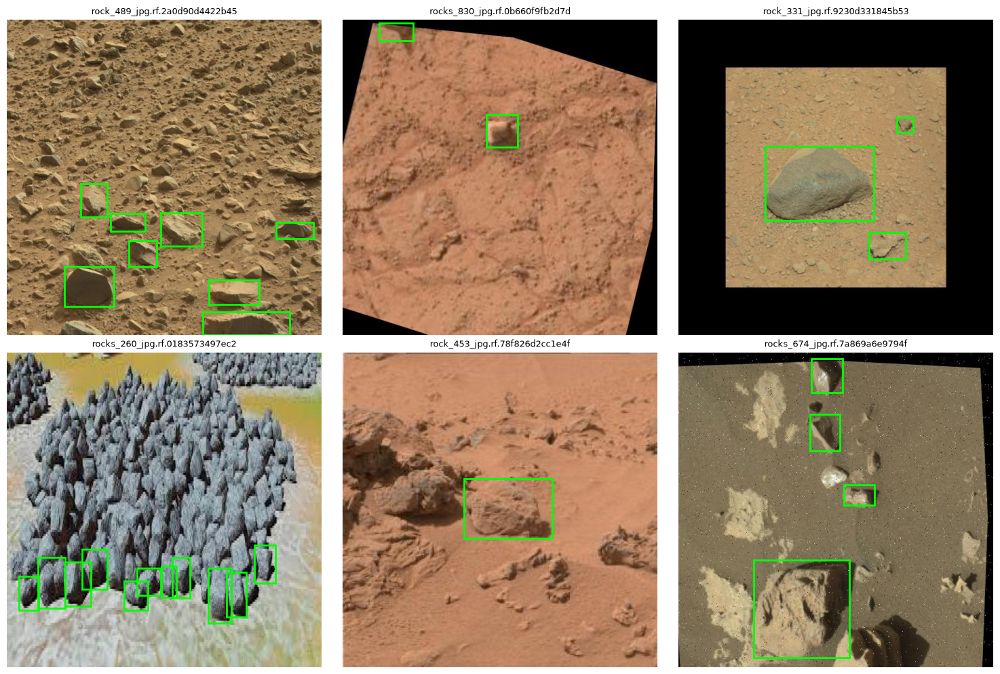

In [10]:
def read_boxes(label_path):
    boxes = []
    if not label_path.exists():
        return boxes
    for line in label_path.read_text().splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        v = [float(x) for x in p[1:]]
        if len(v) == 4:
            xc, yc, w, h = v
        else:
            xs, ys = v[0::2], v[1::2]
            xc, yc = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
            w, h = max(xs) - min(xs), max(ys) - min(ys)
        boxes.append((xc, yc, w, h))
    return boxes


def show_labeled(n=6, seed=1):
    folder = SPLIT_DIRS["train"]
    paths = sorted(p for p in (DATASET_DIR / folder / "images").iterdir() if p.suffix.lower() in IMG_EXTS)
    chosen = random.Random(seed).sample(paths, min(n, len(paths)))
    cols = 3
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, p in zip(axes, chosen):
        img = Image.open(p).convert("RGB")
        W, H = img.size
        ax.imshow(img)
        for xc, yc, w, h in read_boxes(DATASET_DIR / folder / "labels" / f"{p.stem}.txt"):
            ax.add_patch(plt.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H,
                                       fill=False, linewidth=2, edgecolor="lime"))
        ax.set_title(p.name[:30], fontsize=9)
    plt.tight_layout()
    plt.show()

show_labeled(6)

## 4. Train

This starts from COCO-pretrained YOLO26n weights, not from scratch. Training stops early if validation stops improving. On a GPU this should take a short while. On a CPU it will be slow, so use a hosted GPU if you have one.

In [11]:
model = YOLO(MODEL_NAME)

model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    patience=PATIENCE,
    seed=SEED,
    device=DEVICE,
    workers=WORKERS,
    cache=False,
    amp=True,
    project="runs/erc_rock",
    name="mars_rocks_yolo26n",
    exist_ok=True,
    plots=True,
)

BEST_PATH = Path(model.trainer.best)
print("Best weights:", BEST_PATH)
best_model = YOLO(str(BEST_PATH))

Ultralytics 8.4.173  Python-3.12.10 torch-2.11.0+cpu CPU (13th Gen Intel Core i7-13620H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=mars_rocks\_yolo\rock.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=mars_rocks_yolo26n, nbs=64, nms=None, opset=None, optimi

## 5. Evaluate

Metrics for object detection:

- **Precision**: of the boxes the model drew, how many were real rocks
- **Recall**: of the real rocks, how many the model found
- **F1**: one number that balances precision and recall
- **mAP50**: overall quality when a box counts as correct if it overlaps the real box by at least 50 percent
- **mAP50-95**: the same, but stricter

Plain "accuracy" is not used for object detection, because there is no fixed set of true negatives in an image.

For the rover, recall matters most. A missed rock is a lost candidate, while a few false boxes can be rejected later by the depth stage.

In [7]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from ultralytics import YOLO

IMG_SIZE = 640
DATA_YAML = Path("mars_rocks/_yolo/rock.yaml")
if not DATA_YAML.exists():
    raise FileNotFoundError(f"Dataset YAML not found: {DATA_YAML.resolve()}")
SPLIT_DIRS = {"test": "test"} if (DATA_YAML.parent / "test" / "images").exists() else {}

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

IMG_SIZE = 640
CONF = 0.25
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MARSYARD_DIR = Path("./marsyard_images")

BEST_PATH = Path("runs/detect/runs/erc_rock/mars_rocks_yolo26n/weights/best.pt")
if "best_model" not in globals():
    if not BEST_PATH.exists():
        raise FileNotFoundError(f"Saved model not found: {BEST_PATH.resolve()}")
    best_model = YOLO(str(BEST_PATH))
    print("Loaded saved model:", BEST_PATH.resolve())

def evaluate(split):
    m = best_model.val(data=str(DATA_YAML), split=split, imgsz=IMG_SIZE, plots=True, verbose=False)
    p, r = float(m.box.mp), float(m.box.mr)
    return {
        "split": split,
        "precision": round(p, 3),
        "recall": round(r, 3),
        "F1": round(2 * p * r / (p + r + 1e-12), 3),
        "mAP50": round(float(m.box.map50), 3),
        "mAP50-95": round(float(m.box.map), 3),
    }

results = [evaluate("val")]
if "test" in SPLIT_DIRS:
    results.append(evaluate("test"))
display(pd.DataFrame(results))

Ultralytics 8.4.173  Python-3.12.10 torch-2.11.0+cpu CPU (13th Gen Intel Core i7-13620H)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 122.824.0 MB/s, size: 57.1 KB)
val: Scanning C:\Users\amirf\Desktop\RoboTeam\Rock detection\mars_rocks\_yolo\valid\labels.cache... 351 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 351/351  0.0s
val: C:\Users\amirf\Desktop\RoboTeam\Rock detection\mars_rocks\_yolo\valid\images\rocks_680_jpg.rf.14c39b008ef07f8a73756832c65da1d6.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 1.5it/s 14.4s0.6s
                   all        351       1744       0.86      0.789      0.847      0.655
Speed: 0.9ms preprocess, 32.6ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to C:\Users\amirf\Desktop\RoboTeam\Rock detection\runs\detect\val-3
Ultralytics 8.4.173  Python-3

,split,precision,recall,F1,mAP50,mAP50-95
0,val,0.860,0.789,0.823,0.847,0.655
1,test,0.878,0.766,0.818,0.841,0.647


## 6. Test on your own Mars Yard photos

Put your photos in the folder set by `MARSYARD_DIR` (default `./marsyard_images`) and run the cell. Look for:

- rocks that are missed
- boxes on gravel or soil that are not rocks
- two touching rocks merged into one box
- one big box around a pile
- rocks with a colour the model does not know (the dataset has some different colours)

Try a lower `CONF` (for example 0.15) to see whether more rocks appear, and a higher one to see whether false boxes disappear.

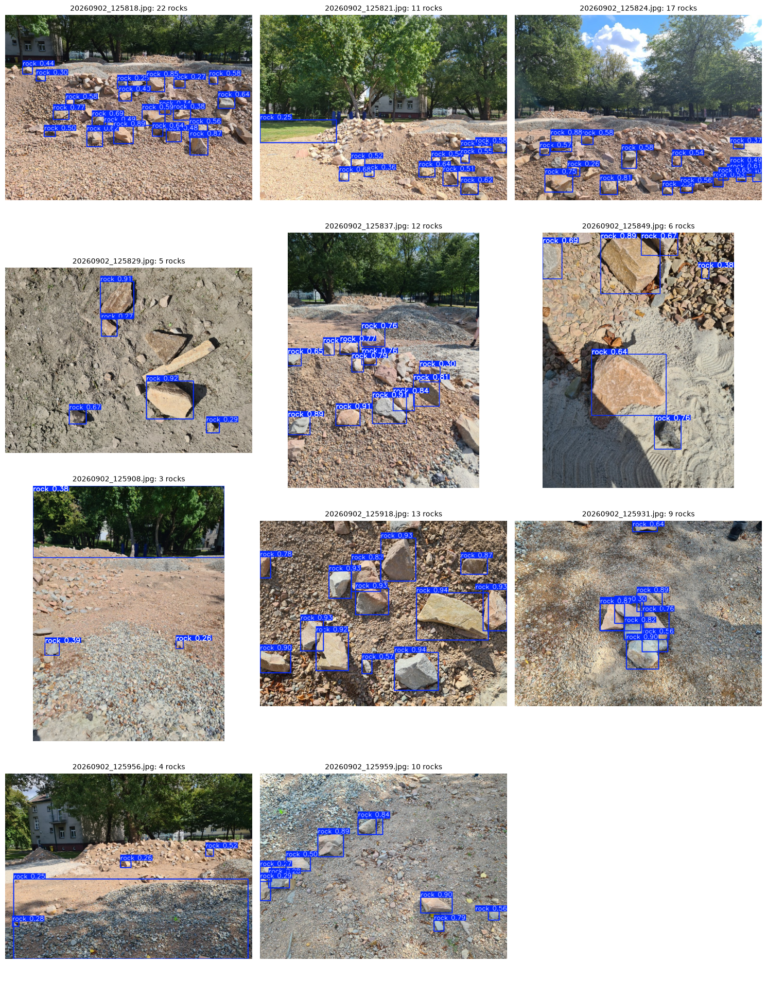

In [8]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

IMG_SIZE = 640
CONF = 0.25
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MARSYARD_DIR = Path("./marsyard_images")

BEST_PATH = Path("runs/detect/runs/erc_rock/mars_rocks_yolo26n/weights/best.pt")
if "best_model" not in globals():
    if not BEST_PATH.exists():
        raise FileNotFoundError(f"Saved model not found: {BEST_PATH.resolve()}")
    best_model = YOLO(str(BEST_PATH))
    print("Loaded saved model:", BEST_PATH.resolve())

def predict_folder(folder, conf=CONF, max_images=12):
    folder = Path(folder)
    if not folder.exists():
        print(f"Folder not found: {folder.resolve()}")
        return
    paths = sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS)[:max_images]
    if not paths:
        print("No images found in", folder.resolve())
        return
    results = best_model.predict(source=[str(p) for p in paths], imgsz=IMG_SIZE, conf=conf, verbose=False)
    cols = 3
    rows = int(np.ceil(len(results) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, p, r in zip(axes, paths, results):
        ax.imshow(r.plot()[:, :, ::-1])
        ax.set_title(f"{p.name}: {len(r.boxes)} rocks", fontsize=10)
    plt.tight_layout()
    plt.show()

predict_folder(MARSYARD_DIR, conf=CONF)

## 7. Demo: upload one photo

Upload an image and the model draws a box around each rock it finds. The numbers are pixel coordinates `[x1, y1, x2, y2]`, which the depth stage will use later.

Loaded saved model: /home/amir_frf/Roboteam/rock detection model/runs/detect/runs/erc_rock/mars_rocks_yolo26n/weights/best.pt


FileUpload(value=(), accept='image/*', description='Upload image')

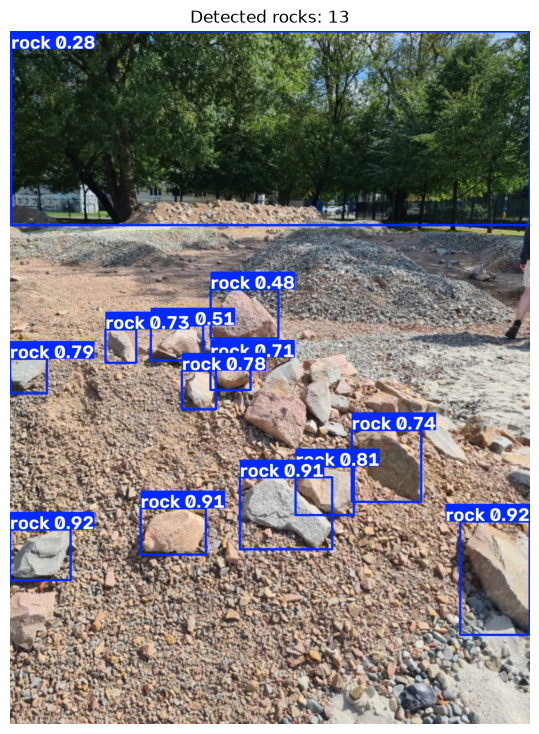

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from ultralytics import YOLO

IMG_SIZE = 640
CONF = 0.25
BEST_PATH = Path("runs/detect/runs/erc_rock/mars_rocks_yolo26n/weights/best.pt")
if not BEST_PATH.exists():
    raise FileNotFoundError(f"Saved model not found: {BEST_PATH.resolve()}")
demo_model = YOLO(str(BEST_PATH))
print("Loaded saved model:", BEST_PATH.resolve())

def run_demo(change=None, conf=CONF):
    value = demo_uploader.value
    if not value:
        return
    item = next(iter(value.values())) if isinstance(value, dict) else value[0]
    demo_dir = Path("./demo_uploads")
    demo_dir.mkdir(exist_ok=True)
    path = demo_dir / item["name"]
    path.write_bytes(bytes(item["content"]))

    result = demo_model.predict(source=str(path), imgsz=IMG_SIZE, conf=conf, verbose=False)[0]
    plt.figure(figsize=(14, 9))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.title(f"Detected rocks: {len(result.boxes)}")
    plt.show()

    for i, box in enumerate(result.boxes, start=1):
        print(f"Rock {i}: confidence={float(box.conf[0]):.2f}, box={box.xyxy[0].cpu().numpy().round(1).tolist()}")

demo_uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Upload image")
demo_uploader.observe(run_demo, names="value")
display(demo_uploader)